# Model 2 — one hidden layer of 256 over learned square embeddings

CW-231 (architecture) and CW-232 (training).

The reusable halves live in `ml/scripts/` and are imported, not restated here: `encode.py` turns a FEN into 64 categorical squares plus five binary inputs, and `targets.py` holds `asinh(cp / 1000)` and its exact inverse. Everything specific to this experiment — the model, the optimizer, the loop, the parameters, the plots — is in this notebook.

Run top to bottom from a fresh kernel; that is the form the recorded numbers refer to. `final_test.csv` is never opened here.

In [13]:
import csv, json, time
import sys
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn

# ml/ is the root whether the notebook is opened from ml/ or ml/notebooks/.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))

from canonical import MAX_CP
from encode import CATEGORIES, EMBED_DIM, FEATURES, INPUT_SIZE, SQUARES, encode
from targets import S, to_cp, to_target

DATA = ROOT / "data"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

# Four physical cores. The model is 133k parameters, so this is CPU work and a
# GPU would buy nothing; the thread count is pinned so epoch times stay
# comparable between runs rather than depending on what else is open.
torch.set_num_threads(4)
print(torch.__version__, "| inputs", INPUT_SIZE)

2.14.1+cpu | inputs 517


## Experiment parameters

One dict, written beside the checkpoint on every save. CW-232 asks for the configuration recorded rather than remembered, and for the run to be repeatable from the dataset files alone — the seed below, plus an encoder that is a pure function of the FEN, is what makes that true.

In [14]:
CONFIG = {
    "seed": 20261001,
    "embed_dim": EMBED_DIM,          # 8, from encode.py — not a second opinion
    "hidden": 256,
    "batch_size": 512,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "max_epochs": 60,
    "patience": 6,                   # epochs without improvement before stopping
    "optimizer": "AdamW",
    "loss": "MSE on asinh(cp / S)",
    "S": S,
}
CONFIG

{'seed': 20261001,
 'embed_dim': 8,
 'hidden': 256,
 'batch_size': 512,
 'lr': 0.001,
 'weight_decay': 0.0001,
 'max_epochs': 60,
 'patience': 6,
 'optimizer': 'AdamW',
 'loss': 'MSE on asinh(cp / S)',
 'S': 1000}

## Dataset loading

The rows are read separately from the tensors because the validation FENs and their original integer targets are wanted again at the end, for the predictions file. Everything else works off the tensors.

In [15]:
def rows_of(split):
    """A split as (fen, target_value) pairs, in the file's own order.

    That order is (game_id, ply), inherited from the labeled file, so anything
    written back out alongside these rows lines up with the dataset.
    """
    with open(DATA / f"final_{split}.csv", newline="", encoding="utf-8") as fh:
        reader = csv.reader(fh)
        next(reader)                                   # fen,target_value
        return [(fen, int(target)) for fen, target in reader]


def load(rows):
    """Rows to tensors, encoded once up front.

    600,000 rows at 69 values is 41 MB as uint8, so the whole dataset lives in
    memory and every epoch after this is pure tensor arithmetic. Encoding inside
    the training loop would make a Python function call the bottleneck and hide
    what the model itself costs.

    Squares stay uint8 and are cast to long per batch: nn.Embedding needs int64
    indices, and holding 500,000 rows as int64 would be 256 MB for exactly the
    same information.
    """
    squares, flags, targets = [], [], []
    for fen, target in rows:
        position = encode(fen)
        squares.append(position.squares)
        flags.append((position.side_to_move,) + position.castling)
        # The one place centipawns become targets. Raw cp never enters a tensor,
        # so "loss is never computed on raw centipawns" holds by construction
        # rather than by remembering.
        targets.append(to_target(target))
    return (
        torch.from_numpy(np.array(squares, dtype=np.uint8)),
        torch.from_numpy(np.array(flags, dtype=np.float32)),
        torch.from_numpy(np.array(targets, dtype=np.float32)).unsqueeze(1),
    )


started = time.time()
train = load(rows_of("train"))       # the row list is not kept; only val's is
val_rows = rows_of("val")
val = load(val_rows)
# final_test.csv is deliberately not opened in this notebook. CW-164 froze it,
# and the simplest enforcement of that is its absence.
print(f"loaded and encoded in {time.time() - started:.0f}s")
print("train", tuple(train[0].shape), tuple(train[1].shape), tuple(train[2].shape))
print("val  ", tuple(val[0].shape), tuple(val[1].shape), tuple(val[2].shape))

loaded and encoded in 11s
train (500000, 64) (500000, 5) (500000, 1)
val   (50000, 64) (50000, 5) (50000, 1)


In [16]:
# Against the dataset's own measured numbers. A mate fraction far from 4.7% or a
# side-to-move split far from 49.8% would mean the encoder and the CSV disagree
# about what a row is — the one failure that would otherwise train quietly and
# evaluate nonsense.
squares, flags, targets = train
assert squares.shape[1] + flags.shape[1] == FEATURES == 69
assert 0 <= int(squares.min()) and int(squares.max()) < CATEGORIES
assert set(flags.unique().tolist()) <= {0.0, 1.0}

print(f"target  mean {targets.mean():+.4f}  std {targets.std():.4f}  "
      f"min {targets.min():+.4f}  max {targets.max():+.4f}")
median = float(targets.abs().median())
print(f"        median |target| {median:.4f}  ->  {to_cp(median):.0f} cp")
mates = (targets.abs() > to_target(MAX_CP)).float().mean()
print(f"mate band        {100 * mates:.1f}% of rows (expected 4.7%)")
print(f"White to move    {100 * flags[:, 0].mean():.1f}% (expected 49.8%)")

target  mean +0.0582  std 0.7998  min -3.0637  max +3.0637
        median |target| 0.2861  ->  290 cp
mate band        4.7% of rows (expected 4.7%)
White to move    49.8% (expected 49.8%)


## Model architecture (CW-231)

A shared embedding over the 13 square categories, flattened and concatenated with side to move and the four castling bits, through exactly one hidden layer of 256 ReLU units, to a single output with no activation.

In [17]:
class Model2(nn.Module):
    """Embedding(13, 8) shared across all 64 squares -> 512, plus 5 -> 517,
    Linear(517, 256) + ReLU, Linear(256, 1).

    The output carries no activation. Evaluations are signed, and the target
    spans roughly -3.06 to +3.06 after the asinh transform, so anything that
    bounded the output below that range would cap the model's own range.
    """

    def __init__(self, categories=CATEGORIES, embed_dim=EMBED_DIM,
                 hidden=CONFIG["hidden"]):
        super().__init__()
        self.embed = nn.Embedding(categories, embed_dim)
        self.hidden = nn.Linear(SQUARES * embed_dim + 5, hidden)
        self.out = nn.Linear(hidden, 1)
        # Kaiming with the ReLU gain, which is what this layer actually feeds.
        # PyTorch's default assumes leaky_relu with a = sqrt(5) and leaves the
        # activations smaller than they should be.
        nn.init.kaiming_uniform_(self.hidden.weight, nonlinearity="relu")
        nn.init.zeros_(self.hidden.bias)

    def forward(self, squares, flags):
        x = self.embed(squares.long()).flatten(1)      # (B, 64, 8) -> (B, 512)
        x = torch.cat([x, flags], dim=1)               # (B, 517)
        return self.out(torch.relu(self.hidden(x)))


torch.manual_seed(CONFIG["seed"])
model = Model2()

# The 517 here has to be the 517 in encode.py, or CW-236's C++ evaluator would
# be porting a different model than the one trained.
assert model.hidden.in_features == INPUT_SIZE
parameters = sum(p.numel() for p in model.parameters())
CONFIG["parameters"] = parameters
print(model)
print(f"\n{parameters:,} parameters — {len(train[0]) / parameters:.1f} training rows each")

Model2(
  (embed): Embedding(13, 8)
  (hidden): Linear(in_features=517, out_features=256, bias=True)
  (out): Linear(in_features=256, out_features=1, bias=True)
)

132,969 parameters — 3.8 training rows each


## Optimizer, loss, and the validation pass

The loss at initialisation should sit near the variance of the target: an untrained model predicts roughly the mean, and mean squared error against the mean *is* the variance. A number far from it means the output head is badly scaled, which is worth knowing before spending sixty epochs on it.

In [18]:
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"],
                              weight_decay=CONFIG["weight_decay"])
criterion = nn.MSELoss()


@torch.no_grad()
def evaluate(data, chunk=8192):
    """Mean squared error over a whole split, in transformed space."""
    model.eval()
    squares, flags, targets = data
    total = 0.0
    for i in range(0, len(squares), chunk):
        predicted = model(squares[i:i + chunk], flags[i:i + chunk])
        total += criterion(predicted, targets[i:i + chunk]).item() * len(predicted)
    return total / len(squares)


print(f"val loss at init  {evaluate(val):.4f}")
print(f"target variance   {val[2].var():.4f}")

val loss at init  0.7239
target variance   0.6350


## Training loop (CW-232)

Training runs on the training split only, validation error is measured every epoch, and the epoch kept is the one with the lowest validation error — not the last one, which is on the far side of wherever overfitting started.

In [19]:
CHECKPOINT = MODELS / "model2.pt"
HISTORY = MODELS / "model2_history.json"

generator = torch.Generator().manual_seed(CONFIG["seed"])
squares, flags, targets = train
n, batch = len(squares), CONFIG["batch_size"]

history, best, best_epoch = [], float("inf"), 0
started = time.time()

for epoch in range(1, CONFIG["max_epochs"] + 1):
    model.train()
    # Seeded shuffle, so the run reproduces from the dataset files alone.
    order = torch.randperm(n, generator=generator)
    running = 0.0
    for i in range(0, n, batch):
        index = order[i:i + batch]
        optimizer.zero_grad()
        loss = criterion(model(squares[index], flags[index]), targets[index])
        loss.backward()
        optimizer.step()
        running += loss.item() * len(index)

    train_loss, val_loss = running / n, evaluate(val)
    history.append({"epoch": epoch, "train": train_loss, "val": val_loss})
    marker = ""

    if val_loss < best:
        best, best_epoch, marker = val_loss, epoch, "  <- best"
        torch.save({"state_dict": model.state_dict(), "config": CONFIG,
                    "epoch": epoch, "val_loss": val_loss}, CHECKPOINT)

    print(f"epoch {epoch:3}  train {train_loss:.5f}  val {val_loss:.5f}"
          f"  {time.time() - started:5.0f}s{marker}")

    if epoch - best_epoch >= CONFIG["patience"]:
        print(f"\nstopping: no improvement in {CONFIG['patience']} epochs")
        break

HISTORY.write_text(json.dumps({"config": CONFIG, "best_epoch": best_epoch,
                               "best_val": best, "history": history}, indent=2))
print(f"\nbest val {best:.5f} at epoch {best_epoch} — saved to {CHECKPOINT.name}")

epoch   1  train 0.63118  val 0.56511     13s  <- best
epoch   2  train 0.38599  val 0.29184     35s  <- best
epoch   3  train 0.27137  val 0.28580     51s  <- best
epoch   4  train 0.25967  val 0.25935     64s  <- best
epoch   5  train 0.25300  val 0.25829     78s  <- best
epoch   6  train 0.24776  val 0.26140     94s
epoch   7  train 0.24280  val 0.26437    114s
epoch   8  train 0.23725  val 0.25962    134s
epoch   9  train 0.22950  val 0.26137    154s
epoch  10  train 0.22305  val 0.26200    184s
epoch  11  train 0.21522  val 0.27133    201s

stopping: no improvement in 6 epochs

best val 0.25829 at epoch 5 — saved to model2.pt


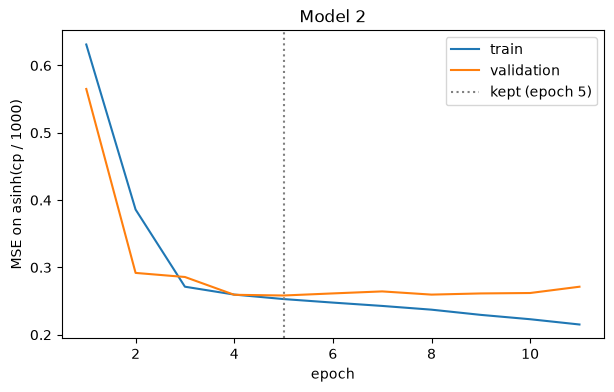

In [20]:
import matplotlib.pyplot as plt

epochs = [h["epoch"] for h in history]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, [h["train"] for h in history], label="train")
ax.plot(epochs, [h["val"] for h in history], label="validation")
ax.axvline(best_epoch, color="grey", linestyle=":",
           label=f"kept (epoch {best_epoch})")
ax.set(xlabel="epoch", ylabel="MSE on asinh(cp / 1000)", title="Model 2")
ax.legend()
plt.show()

## Validation error in centipawns

A mean squared error in asinh space means nothing to a reader, so the predictions go back through the exact inverse and are reported in the units the rest of the project speaks. The full bucketed table and the classification comparison are CW-234; this is the headline number, taken from the kept checkpoint rather than from whatever the loop last left in memory.

In [21]:
model.load_state_dict(torch.load(CHECKPOINT, weights_only=True)["state_dict"])
model.eval()
with torch.no_grad():
    predicted = torch.cat([model(val[0][i:i + 8192], val[1][i:i + 8192])
                           for i in range(0, len(val[0]), 8192)])

predicted_cp = S * torch.sinh(predicted.squeeze(1))
actual_cp = S * torch.sinh(val[2].squeeze(1))
error = (predicted_cp - actual_cp).abs()

print(f"median absolute error  {error.median():8.1f} cp")
print(f"mean   absolute error  {error.mean():8.1f} cp")
disagree = ((predicted_cp > 0) != (actual_cp > 0)).float().mean()
print(f"sign disagreement      {100 * disagree:8.1f}%")

median absolute error     174.4 cp
mean   absolute error     620.2 cp
sign disagreement          22.9%


## Real against predicted, one row per validation position

Written out so the error can be looked at outside the notebook — sorted, filtered, opened in a spreadsheet — rather than only summarised by the numbers above.

`actual_cp` is the dataset's `target_value`, taken from the CSV as the integer it is rather than round-tripped through the transform, so the comparison carries none of our own arithmetic. For the 4.7% of rows that are mates, that value is the mate-band encoding (10,010 to 10,680) rather than a centipawn score the engine reported — hence `is_mate`, which is the column to filter on before reading any average.

In [10]:
PREDICTIONS = MODELS / "model2_val_predictions.csv"

# load() preserved the order it was given and the predictions were built by
# walking the tensors in order, so row i of each is the same position. The
# assert is here because a silent misalignment would look like a badly trained
# model rather than like a bug.
assert len(val_rows) == len(predicted_cp)

with open(PREDICTIONS, "w", newline="", encoding="utf-8") as fh:
    writer = csv.writer(fh)
    writer.writerow(("fen", "actual_cp", "predicted_cp", "error_cp", "is_mate"))
    for (fen, actual), prediction in zip(val_rows, predicted_cp.tolist()):
        writer.writerow((fen, actual, round(prediction, 1),
                         round(prediction - actual, 1),
                         int(abs(actual) > MAX_CP)))

print(f"{len(val_rows):,} rows -> {PREDICTIONS}  "
      f"({PREDICTIONS.stat().st_size / 1e6:.1f} MB)")
with open(PREDICTIONS, encoding="utf-8") as fh:
    for _ in range(4):
        print("  " + next(fh).rstrip())

50,000 rows -> c:\Users\Uziel\Desktop\Projects\Chess Project\ml\models\model2_val_predictions.csv  (3.9 MB)
  fen,actual_cp,predicted_cp,error_cp,is_mate
  r2qk1nr/1pp2ppp/p1pb4/4p3/3PP1b1/4BN2/PPP2PPP/RN1QK2R b KQkq - 0 7,54,137.8,83.8,0
  2kr3r/1pp1npp1/p1p2q1p/4N2b/4P3/2P1B2P/PPQN1PP1/R4RK1 b - - 0 14,-162,-249.6,-87.6,0
  2k5/2p1npp1/p1p4p/1p5b/2N1PP2/2Pr3P/PP3BP1/5RK1 w - - 0 21,340,81.6,-258.4,0
